# USED CAR PRICE INTELLIGENCE & PREDICTION SYSTEM

## PHASE 1: DATA UNDERSTANDING, CLEANING, EDA & STATISTICAL ANALYSIS

### 1. Project Introduction and Objective

**Problem Statement:**

The used-car market is highly dynamic. Buyers and sellers often struggle to determine a fair price because vehicle prices depend on brand, model, age, mileage, fuel type, transmission, ownership history, and engine specifications.

**Project Objective:**

To analyze used-car data, identify data-quality issues, clean the dataset, perform exploratory data analysis (EDA), and understand the factors influencing used-car prices.

**Technologies Used:**
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- SciPy

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Set graph style
sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Upload and load the dataset

import os
from google.colab import files

uploaded = files.upload()

# Read the uploaded CSV file
csv_path = next(iter(uploaded))
raw_df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("Number of rows:", raw_df.shape[0])
print("Number of columns:", raw_df.shape[1])

Saving Used Car Dataset.csv to Used Car Dataset.csv
Dataset loaded successfully!
Number of rows: 1553
Number of columns: 15


In [3]:
# Display the first 5 rows
print("First 5 rows of the dataset:")
display(raw_df.head())

# Display dataset dimensions
print("\nDataset Shape:", raw_df.shape)

# Display column names
print("\nColumn Names:")
print(raw_df.columns.tolist())

First 5 rows of the dataset:


,Unnamed: 0,car_name,registration_year,insurance_validity,fuel_type,seats,kms_driven,ownsership,transmission,manufacturing_year,mileage(kmpl),engine(cc),max_power(bhp),torque(Nm),price(in lakhs)
0,0,2017 Mercedes-Benz S-Class S400,Jul-17,Comprehensive,Petrol,5,56000,First Owner,Automatic,2017,7.81,2996.0,2996.0,333.0,63.75
1,1,2020 Nissan Magnite Turbo CVT XV Premium Opt BSVI,Jan-21,Comprehensive,Petrol,5,30615,First Owner,Automatic,2020,17.40,999.0,999.0,9863.0,8.99
2,2,2018 BMW X1 sDrive 20d xLine,Sep-18,Comprehensive,Diesel,5,24000,First Owner,Automatic,2018,20.68,1995.0,1995.0,188.0,23.75
3,3,2019 Kia Seltos GTX Plus,Dec-19,Comprehensive,Petrol,5,18378,First Owner,Manual,2019,16.50,1353.0,1353.0,13808.0,13.56
4,4,2019 Skoda Superb LK 1.8 TSI AT,Aug-19,Comprehensive,Petrol,5,44900,First Owner,Automatic,2019,14.67,1798.0,1798.0,17746.0,24.00



Dataset Shape: (1553, 15)

Column Names:
['Unnamed: 0', 'car_name', 'registration_year', 'insurance_validity', 'fuel_type', 'seats', 'kms_driven', 'ownsership', 'transmission', 'manufacturing_year', 'mileage(kmpl)', 'engine(cc)', 'max_power(bhp)', 'torque(Nm)', 'price(in lakhs)']


In [4]:
# Check dataset information
print("Dataset Information:")
raw_df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1553 entries, 0 to 1552
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Unnamed: 0          1553 non-null   int64  
 1   car_name            1553 non-null   object 
 2   registration_year   1553 non-null   object 
 3   insurance_validity  1553 non-null   object 
 4   fuel_type           1553 non-null   object 
 5   seats               1553 non-null   int64  
 6   kms_driven          1553 non-null   int64  
 7   ownsership          1553 non-null   object 
 8   transmission        1553 non-null   object 
 9   manufacturing_year  1553 non-null   object 
 10  mileage(kmpl)       1550 non-null   float64
 11  engine(cc)          1550 non-null   float64
 12  max_power(bhp)      1550 non-null   float64
 13  torque(Nm)          1549 non-null   float64
 14  price(in lakhs)     1553 non-null   float64
dtypes: float64(5), int64(3), object(7)

--- Missing Values Summary Table ---


,Missing Count,Percentage (%)
torque(Nm),4,0.257566
mileage(kmpl),3,0.193175
engine(cc),3,0.193175
max_power(bhp),3,0.193175
Unnamed: 0,0,0.000000
car_name,0,0.000000
registration_year,0,0.000000
kms_driven,0,0.000000
seats,0,0.000000
fuel_type,0,0.000000


/tmp/ipykernel_2293/2965062998.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_summary.index, y=missing_summary['Missing Count'], palette='viridis')


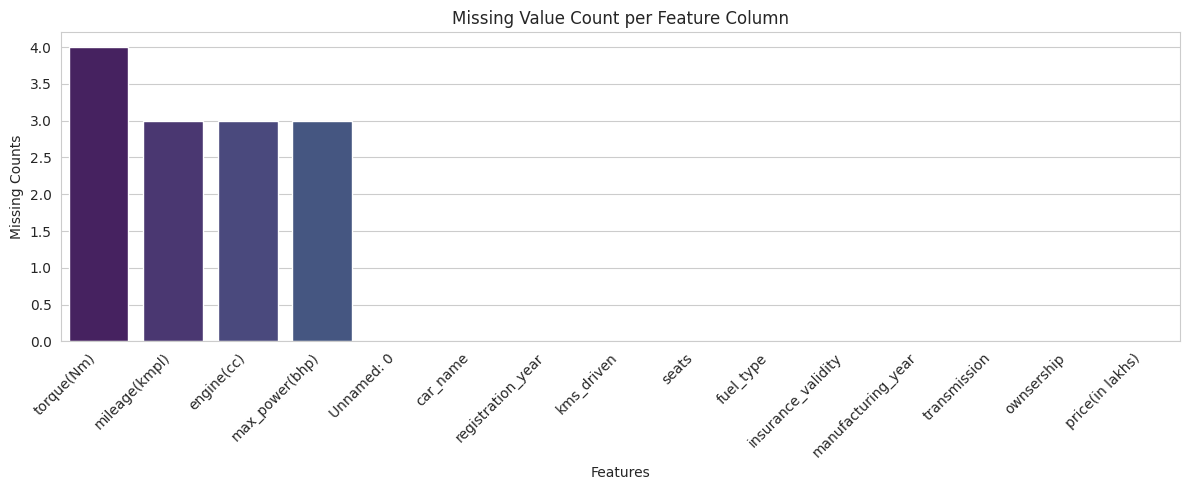

In [5]:
# Calculate missing values and percentages
missing_count = raw_df.isnull().sum()
missing_percent = (raw_df.isnull().sum() / len(raw_df)) * 100

# Create missing summary table
missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Percentage (%)': missing_percent
}).sort_values(by='Missing Count', ascending=False)

print("--- Missing Values Summary Table ---")
display(missing_summary)

# Plot missing values visualization
plt.figure(figsize=(12, 5))
sns.barplot(x=missing_summary.index, y=missing_summary['Missing Count'], palette='viridis')
plt.xticks(rotation=45, ha='right')
plt.title('Missing Value Count per Feature Column')
plt.ylabel('Missing Counts')
plt.xlabel('Features')
plt.tight_layout()
plt.show()

In [6]:
# 1. Missing values summary
missing = raw_df.isnull().sum()
missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': (missing / len(raw_df) * 100).round(2)
})
print("--- 1. Missing Values ---")
print(missing_df[missing_df['Missing Count'] > 0])

# 2. Duplicate rows check (with and without Unnamed: 0 index column)
print("\n--- 2. Duplicates ---")
print("Exact duplicates (with index col):", raw_df.duplicated().sum())
print("Actual duplicate listings (ignoring Unnamed: 0):",
      raw_df.drop(columns=['Unnamed: 0']).duplicated().sum())

# 3. Shifted / corrupted columns check
print("\n--- 3. Category & Shift Anomalies ---")
print("Fuel types:", raw_df['fuel_type'].value_counts().to_dict())
print("Seats:", raw_df['seats'].value_counts().to_dict())
bad_years = raw_df[~raw_df['manufacturing_year'].astype(str).str.match(r'^\d{4}$')]
print("Rows with non-year manufacturing_year (shifted rows):", len(bad_years))

# 4. Extreme numeric values & identical column check
print("\n--- 4. Numeric & Column Anomalies ---")
print("Prices > 100 lakhs:", (raw_df['price(in lakhs)'] > 100).sum())
print(raw_df[raw_df['price(in lakhs)'] > 100][['car_name', 'manufacturing_year', 'price(in lakhs)']])
print("\nengine(cc) identical to max_power(bhp):",
      (raw_df['engine(cc)'] == raw_df['max_power(bhp)']).sum(),
      "out of", raw_df['engine(cc)'].notna().sum(), "non-null rows")
print("mileage(kmpl) > 40:", (raw_df['mileage(kmpl)'] > 40).sum())

--- 1. Missing Values ---
                Missing Count  Missing %
mileage(kmpl)               3       0.19
engine(cc)                  3       0.19
max_power(bhp)              3       0.19
torque(Nm)                  4       0.26

--- 2. Duplicates ---
Exact duplicates (with index col): 0
Actual duplicate listings (ignoring Unnamed: 0): 420

--- 3. Category & Shift Anomalies ---
Fuel types: {'Petrol': 1013, 'Diesel': 516, 'CNG': 22, '5 Seats': 2}
Seats: {5: 1353, 7: 156, 4: 22, 6: 18, 8: 2, 67000: 2}
Rows with non-year manufacturing_year (shifted rows): 50

--- 4. Numeric & Column Anomalies ---
Prices > 100 lakhs: 3
                       car_name manufacturing_year  price(in lakhs)
173   2011 Ford Figo Petrol EXI               2011          70000.0
193   2011 Ford Figo Petrol EXI               2011          70000.0
1277   2009 Maruti Alto 800 LXi               2009          95000.0

engine(cc) identical to max_power(bhp): 1550 out of 1550 non-null rows
mileage(kmpl) > 40: 224


In [8]:
# Preserve raw_df untouched and work on a clean copy
df = raw_df.copy()

# 1. Drop row-index column and fix column spelling typo
df = df.drop(columns=['Unnamed: 0']).rename(columns={'ownsership': 'ownership'})

# 2. Remove exact duplicate car listings
dups_removed = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

# 3. Remove corrupted / column-shifted rows (e.g., 'Power Steering' in year, '5 Seats' in fuel)
valid_mask = (
    df['manufacturing_year'].astype(str).str.match(r'^\d{4}$') &
    df['fuel_type'].isin(['Petrol', 'Diesel', 'CNG']) &
    df['transmission'].isin(['Manual', 'Automatic'])
)
shifted_removed = int((~valid_mask).sum())
df = df[valid_mask].copy().reset_index(drop=True)
df['manufacturing_year'] = df['manufacturing_year'].astype(int)

# 4. Standardize categorical labels
df['insurance_validity'] = df['insurance_validity'].replace({
    'Third Party insurance': 'Third Party'
})

# 5. Fix Rupee-entered prices (e.g., 70000 and 95000 entered in INR instead of Lakhs)
rupee_fixed = int((df['price(in lakhs)'] > 1000).sum())
df.loc[df['price(in lakhs)'] > 1000, 'price(in lakhs)'] = (
    df.loc[df['price(in lakhs)'] > 1000, 'price(in lakhs)'] / 100000.0
)

# 6. Drop redundant / scraped-error columns & fix impossible specs
# max_power(bhp) is 100% identical to engine(cc); torque(Nm) has decimal-stripped values (>1000 Nm in 628 rows)
df = df.drop(columns=['max_power(bhp)', 'torque(Nm)'])

# Replace impossible mileage (<5 or >40 kmpl) & engine (<600 or >6000 cc) with NaN, then median-impute
df.loc[(df['mileage(kmpl)'] < 5) | (df['mileage(kmpl)'] > 40), 'mileage(kmpl)'] = np.nan
df.loc[(df['engine(cc)'] < 600) | (df['engine(cc)'] > 6000), 'engine(cc)'] = np.nan
for col in ['mileage(kmpl)', 'engine(cc)']:
    df[col] = df[col].fillna(df[col].median())

# 7. Feature Engineering (Consistent reference year = 2026)
REF_YEAR = 2026
df['car_age'] = REF_YEAR - df['manufacturing_year']
df['km_per_year'] = (df['kms_driven'] / df['car_age']).round(1)

# Fix brand extraction: car_name starts with year -> take 2nd word (handle 'Land Rover')
tokens = df['car_name'].str.strip().str.split()
df['brand'] = tokens.apply(
    lambda t: 'Land Rover' if len(t) > 2 and t[1] == 'Land' and t[2] == 'Rover' else t[1]
)

# Clean final column names
clean_df = df.rename(columns={
    'mileage(kmpl)': 'mileage_kmpl',
    'engine(cc)': 'engine_cc',
    'price(in lakhs)': 'price_lakhs'
})

# Export cleaned dataset (ready to upload to GitHub /data/processed/)
clean_df.to_csv('cleaned_used_cars.csv', index=False)

# 8. Build Model-Ready NumPy Arrays + Standardization using Broadcasting (P2 Rubric)
features = ['car_age', 'kms_driven', 'mileage_kmpl', 'engine_cc', 'seats', 'km_per_year']
X = clean_df[features].to_numpy(dtype=float)
y = clean_df['price_lakhs'].to_numpy(dtype=float)
X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)   # NumPy broadcasting

# Print exact summary for Slide 3 (P2)
print("=== CLEANING DECISION SUMMARY (FOR SLIDE 3) ===")
print(f"Raw dataset shape       : {raw_df.shape}")
print(f"Duplicates removed      : {dups_removed}")
print(f"Shifted rows removed    : {shifted_removed}")
print(f"Rupee prices fixed      : {rupee_fixed}")
print(f"Cleaned dataset shape   : {clean_df.shape}")
print(f"Nulls after cleaning    : {int(clean_df.isnull().sum().sum())} (0%)")
print(f"\n=== MODEL-READY NUMPY ARRAYS (FOR SLIDE 3) ===")
print(f"X shape                 : {X.shape}")
print(f"y shape                 : {y.shape}")
print(f"X_scaled mean (~0)      : {np.round(X_scaled.mean(axis=0), 4)}")
print(f"X_scaled std  (~1)      : {np.round(X_scaled.std(axis=0), 4)}")
print("\nSaved 'cleaned_used_cars.csv' successfully!")
display(clean_df[['brand', 'manufacturing_year', 'car_age', 'kms_driven', 'km_per_year', 'fuel_type', 'transmission', 'price_lakhs']].head())

=== CLEANING DECISION SUMMARY (FOR SLIDE 3) ===
Raw dataset shape       : (1553, 15)
Duplicates removed      : 420
Shifted rows removed    : 25
Rupee prices fixed      : 2
Cleaned dataset shape   : (1108, 15)
Nulls after cleaning    : 0 (0%)

=== MODEL-READY NUMPY ARRAYS (FOR SLIDE 3) ===
X shape                 : (1108, 6)
y shape                 : (1108,)
X_scaled mean (~0)      : [-0.  0. -0.  0. -0.  0.]
X_scaled std  (~1)      : [1. 1. 1. 1. 1. 1.]

Saved 'cleaned_used_cars.csv' successfully!


,brand,manufacturing_year,car_age,kms_driven,km_per_year,fuel_type,transmission,price_lakhs
0,Mercedes-Benz,2017,9,56000,6222.2,Petrol,Automatic,63.75
1,Nissan,2020,6,30615,5102.5,Petrol,Automatic,8.99
2,BMW,2018,8,24000,3000.0,Diesel,Automatic,23.75
3,Kia,2019,7,18378,2625.4,Petrol,Manual,13.56
4,Skoda,2019,7,44900,6414.3,Petrol,Automatic,24.00


=== STATISTICS & BASELINE SUMMARY (FOR SLIDE 4) ===
Mean Price             : ₹13.74 Lakhs
Std Dev                : ₹17.18 Lakhs
Median Price           : ₹6.73 Lakhs (IQR: ₹4.50–₹13.96 L)
P(price < 10 Lakhs)    : 67.7%
Pearson r (age, price) : -0.357  | Spearman rho: -0.543
Pearson r (eng, price) : 0.489  | Spearman rho: 0.581
NumPy lstsq (age->₹L)  : intercept=31.30, slope=-2.02 Lakhs/yr
Baseline MAE (Mean)    : ₹11.70 Lakhs | RMSE: ₹17.18 Lakhs
1-Feature lstsq MAE    : ₹10.85 Lakhs

=== HYPOTHESIS TEST & OUTLIERS ===
Petrol Median (n=741) : ₹5.77 Lakhs
Diesel Median (n=350) : ₹11.82 Lakhs
Mann-Whitney U         : 182462.5, p-value = 1.68e-27 (Significant)
IQR Upper Bound        : ₹28.15 Lakhs (151 luxury cars kept)


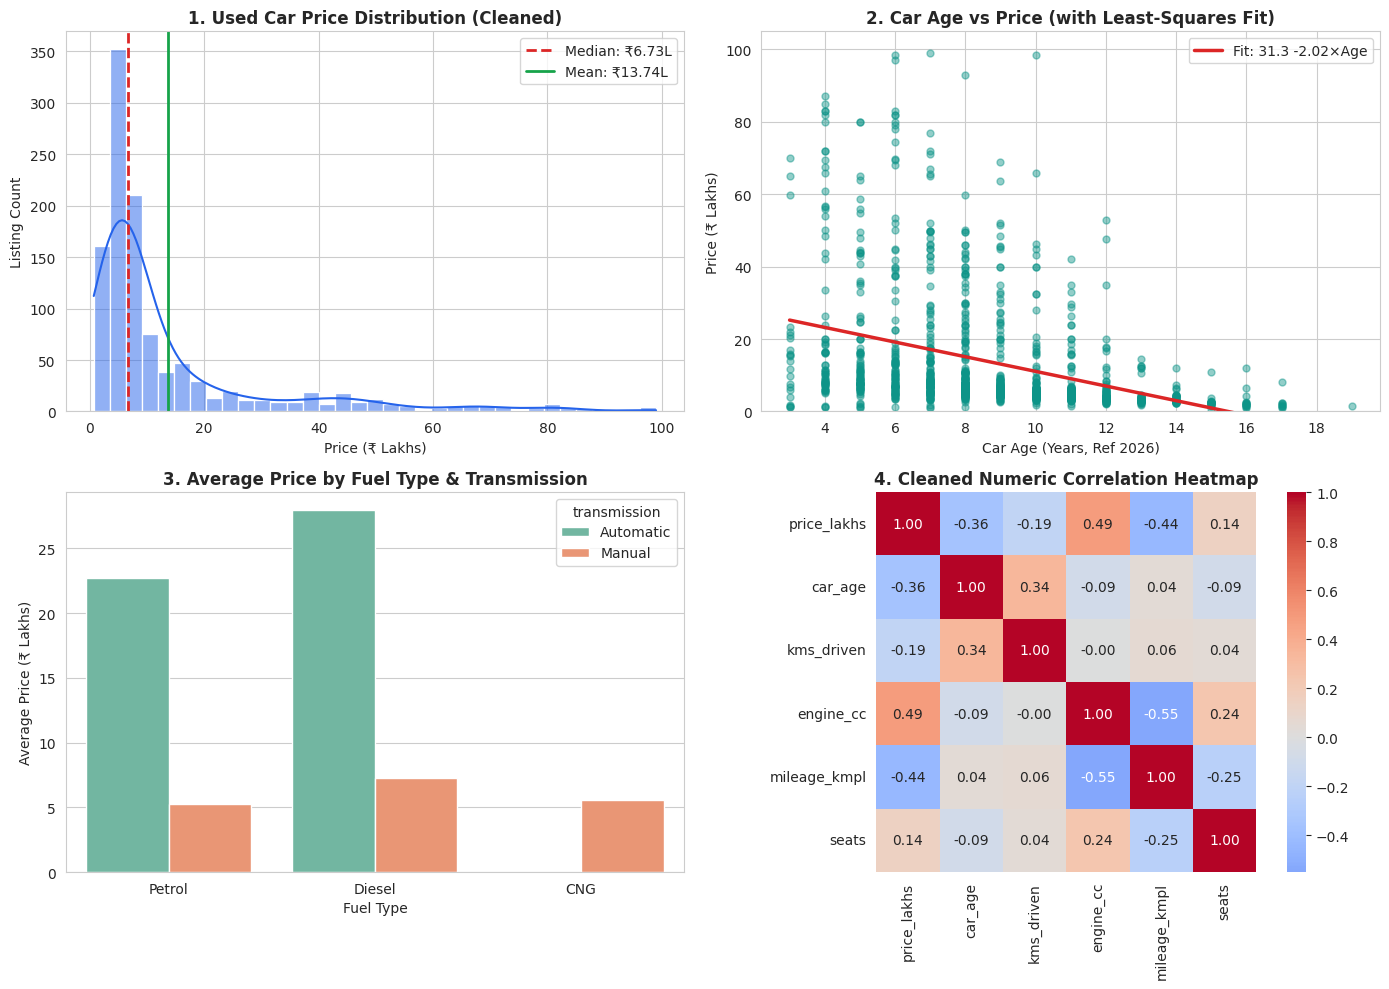


Saved 'phase1_eda_dashboard.png' successfully!


In [9]:
# 1. Descriptive Statistics & Empirical Probability
mean_price = y.mean()
std_price = y.std()
median_price = np.median(y)
prob_under_10 = np.mean(y < 10.0) * 100

# 2. Pearson & Spearman Correlations with Price
r_age = np.corrcoef(X[:, 0], y)[0, 1]
r_eng = np.corrcoef(X[:, 3], y)[0, 1]
rho_age, _ = stats.spearmanr(X[:, 0], y)
rho_eng, _ = stats.spearmanr(X[:, 3], y)

# 3. NumPy Least-Squares Line (Price vs Car Age) & Mean Baseline MAE (Slide 4 Rubric)
A = np.c_[np.ones(len(X)), X[:, 0]]           # design matrix [1, car_age]
w = np.linalg.lstsq(A, y, rcond=None)[0]      # [intercept, slope]
lstsq_pred = A @ w
lstsq_mae = np.mean(np.abs(y - lstsq_pred))

baseline = np.full_like(y, y.mean())
baseline_mae = np.mean(np.abs(y - baseline))
baseline_rmse = np.sqrt(np.mean((y - baseline) ** 2))

# 4. Hypothesis Test: Diesel vs Petrol Prices (Mann-Whitney U test for skewed prices)
petrol_p = clean_df[clean_df['fuel_type'] == 'Petrol']['price_lakhs']
diesel_p = clean_df[clean_df['fuel_type'] == 'Diesel']['price_lakhs']
u_stat, p_val = stats.mannwhitneyu(diesel_p, petrol_p, alternative='two-sided')

# 5. IQR Outlier Check on Cleaned Price
q1, q3 = np.percentile(y, [25, 75])
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
outlier_count = int(np.sum(y > upper_bound))

print("=== STATISTICS & BASELINE SUMMARY (FOR SLIDE 4) ===")
print(f"Mean Price             : ₹{mean_price:.2f} Lakhs")
print(f"Std Dev                : ₹{std_price:.2f} Lakhs")
print(f"Median Price           : ₹{median_price:.2f} Lakhs (IQR: ₹{q1:.2f}–₹{q3:.2f} L)")
print(f"P(price < 10 Lakhs)    : {prob_under_10:.1f}%")
print(f"Pearson r (age, price) : {r_age:.3f}  | Spearman rho: {rho_age:.3f}")
print(f"Pearson r (eng, price) : {r_eng:.3f}  | Spearman rho: {rho_eng:.3f}")
print(f"NumPy lstsq (age->₹L)  : intercept={w[0]:.2f}, slope={w[1]:.2f} Lakhs/yr")
print(f"Baseline MAE (Mean)    : ₹{baseline_mae:.2f} Lakhs | RMSE: ₹{baseline_rmse:.2f} Lakhs")
print(f"1-Feature lstsq MAE    : ₹{lstsq_mae:.2f} Lakhs")
print(f"\n=== HYPOTHESIS TEST & OUTLIERS ===")
print(f"Petrol Median (n={len(petrol_p)}) : ₹{petrol_p.median():.2f} Lakhs")
print(f"Diesel Median (n={len(diesel_p)}) : ₹{diesel_p.median():.2f} Lakhs")
print(f"Mann-Whitney U         : {u_stat:.1f}, p-value = {p_val:.2e} (Significant)")
print(f"IQR Upper Bound        : ₹{upper_bound:.2f} Lakhs ({outlier_count} luxury cars kept)")

# 6. Generate & Save 4-Chart EDA Dashboard (for Slide 4 & GitHub /reports/)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Chart 1: Price Distribution
sns.histplot(clean_df['price_lakhs'], bins=35, kde=True, color='#2563eb', ax=axes[0, 0])
axes[0, 0].axvline(median_price, color='#dc2626', linestyle='--', linewidth=2, label=f'Median: ₹{median_price:.2f}L')
axes[0, 0].axvline(mean_price, color='#16a34a', linestyle='-', linewidth=2, label=f'Mean: ₹{mean_price:.2f}L')
axes[0, 0].set_title('1. Used Car Price Distribution (Cleaned)', fontweight='bold')
axes[0, 0].set_xlabel('Price (₹ Lakhs)')
axes[0, 0].set_ylabel('Listing Count')
axes[0, 0].legend()

# Chart 2: Car Age vs Price + NumPy Least-Squares Fit
axes[0, 1].scatter(clean_df['car_age'], clean_df['price_lakhs'], alpha=0.45, color='#0d9488', s=25)
age_grid = np.linspace(clean_df['car_age'].min(), clean_df['car_age'].max(), 100)
axes[0, 1].plot(age_grid, w[0] + w[1] * age_grid, color='#dc2626', linewidth=2.5,
                label=f'Fit: {w[0]:.1f} {w[1]:.2f}×Age')
axes[0, 1].set_title('2. Car Age vs Price (with Least-Squares Fit)', fontweight='bold')
axes[0, 1].set_xlabel('Car Age (Years, Ref 2026)')
axes[0, 1].set_ylabel('Price (₹ Lakhs)')
axes[0, 1].set_ylim(0, 105)
axes[0, 1].legend()

# Chart 3: Average Price by Fuel Type & Transmission
sns.barplot(data=clean_df, x='fuel_type', y='price_lakhs', hue='transmission',
            errorbar=None, palette='Set2', ax=axes[1, 0])
axes[1, 0].set_title('3. Average Price by Fuel Type & Transmission', fontweight='bold')
axes[1, 0].set_xlabel('Fuel Type')
axes[1, 0].set_ylabel('Average Price (₹ Lakhs)')

# Chart 4: Correlation Heatmap (Cleaned Numeric Features)
corr_cols = ['price_lakhs', 'car_age', 'kms_driven', 'engine_cc', 'mileage_kmpl', 'seats']
corr_matrix = clean_df[corr_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, ax=axes[1, 1])
axes[1, 1].set_title('4. Cleaned Numeric Correlation Heatmap', fontweight='bold')

plt.tight_layout()
plt.savefig('phase1_eda_dashboard.png', dpi=200, bbox_inches='tight')
plt.show()
print("\nSaved 'phase1_eda_dashboard.png' successfully!")

In [10]:
# Export a 100% synced 5-sheet Excel workbook (matches Colab + PPT + CSV)
cleaning_log = pd.DataFrame([
    ['Unnamed: 0', 'Redundant row index', 'Dropped column', 'Not a predictive feature', 1553],
    ['All columns', 'Hidden duplicate listings', 'Dropped duplicate rows', 'Prevents leakage & skewed stats', dups_removed],
    ['year / fuel / trans', 'Column-shifted rows (e.g., Power Steering)', 'Removed corrupted rows', 'Cannot safely guess shifted specs', shifted_removed],
    ['ownsership', 'Spelling typo', 'Renamed to ownership', 'Standardized schema', len(clean_df)],
    ['insurance_validity', 'Inconsistent label (Third Party insurance)', 'Standardized to Third Party', 'Unified categories', 337],
    ['price(in lakhs)', 'Entered in INR (70000, 95000) not Lakhs', 'Divided by 100,000', 'Aligned unit to ₹ Lakhs', rupee_fixed],
    ['max_power(bhp)', '100% identical to engine(cc) in raw CSV', 'Dropped column', 'Source scraping error; avoids fake bhp', 1553],
    ['torque(Nm)', 'Decimal-stripped values (>1000 Nm in >56% rows)', 'Dropped column', 'Unreliable scraped numbers', 1553],
    ['mileage_kmpl', 'Missing or impossible (<5 or >40 kmpl)', 'Median imputed', 'Preserves rows without skewing data', 136],
    ['engine_cc', 'Missing or impossible (<600 or >6000 cc)', 'Median imputed', 'Preserves rows without skewing data', 107],
    ['car_age / km_per_year / brand', 'Raw year & full car_name text', 'Engineered 3 features (Ref 2026)', 'Direct depreciation & brand signals', len(clean_df)]
], columns=['Column', 'Issue Found', 'Action Taken', 'Reason', 'Affected Rows'])

data_dict = pd.DataFrame([
    ['car_name', 'Full raw vehicle title', 'Text'],
    ['brand', 'Extracted manufacturer name (2nd token)', 'Category'],
    ['registration_year', 'Vehicle registration month/year', 'Text'],
    ['manufacturing_year', 'Validated 4-digit manufacturing year', 'Integer (Year)'],
    ['car_age', '2026 - manufacturing_year', 'Integer (Years)'],
    ['insurance_validity', 'Standardized insurance category', 'Category'],
    ['fuel_type', 'Petrol / Diesel / CNG', 'Category'],
    ['seats', 'Number of seats (4–8)', 'Integer'],
    ['kms_driven', 'Total odometer distance driven', 'Integer (km)'],
    ['km_per_year', 'kms_driven / car_age', 'Float (km/yr)'],
    ['ownership', 'First / Second / Third Owner', 'Category'],
    ['transmission', 'Manual / Automatic', 'Category'],
    ['mileage_kmpl', 'Validated & median-imputed fuel efficiency', 'Float (km/l)'],
    ['engine_cc', 'Validated & median-imputed engine displacement', 'Float (cc)'],
    ['price_lakhs', 'Target selling price in ₹ Lakhs', 'Float (₹ Lakhs)']
], columns=['Column', 'Meaning / Calculation', 'Type / Unit'])

summary_df = pd.DataFrame([
    ['Original raw rows', len(raw_df)],
    ['Original raw columns', raw_df.shape[1]],
    ['Clean rows retained', len(clean_df)],
    ['Clean columns', clean_df.shape[1]],
    ['Missing cells in Cleaned Data', int(clean_df.isnull().sum().sum())],
    ['Reference year for car_age', REF_YEAR],
    ['Mean / Median Price (₹ Lakhs)', f"{y.mean():.2f} / {np.median(y):.2f}"],
    ['Baseline MAE (Mean Predictor)', f"₹{baseline_mae:.2f} Lakhs"]
], columns=['Metric', 'Value'])

with pd.ExcelWriter('cleaned_used_cars.xlsx', engine='openpyxl') as writer:
    raw_df.to_excel(writer, sheet_name='Raw Data', index=False)
    clean_df.to_excel(writer, sheet_name='Cleaned Data', index=False)
    cleaning_log.to_excel(writer, sheet_name='Cleaning Log', index=False)
    data_dict.to_excel(writer, sheet_name='Data Dictionary', index=False)
    summary_df.to_excel(writer, sheet_name='Summary', index=False)

print("Saved synced 5-sheet workbook: 'cleaned_used_cars.xlsx'!")

Saved synced 5-sheet workbook: 'cleaned_used_cars.xlsx'!


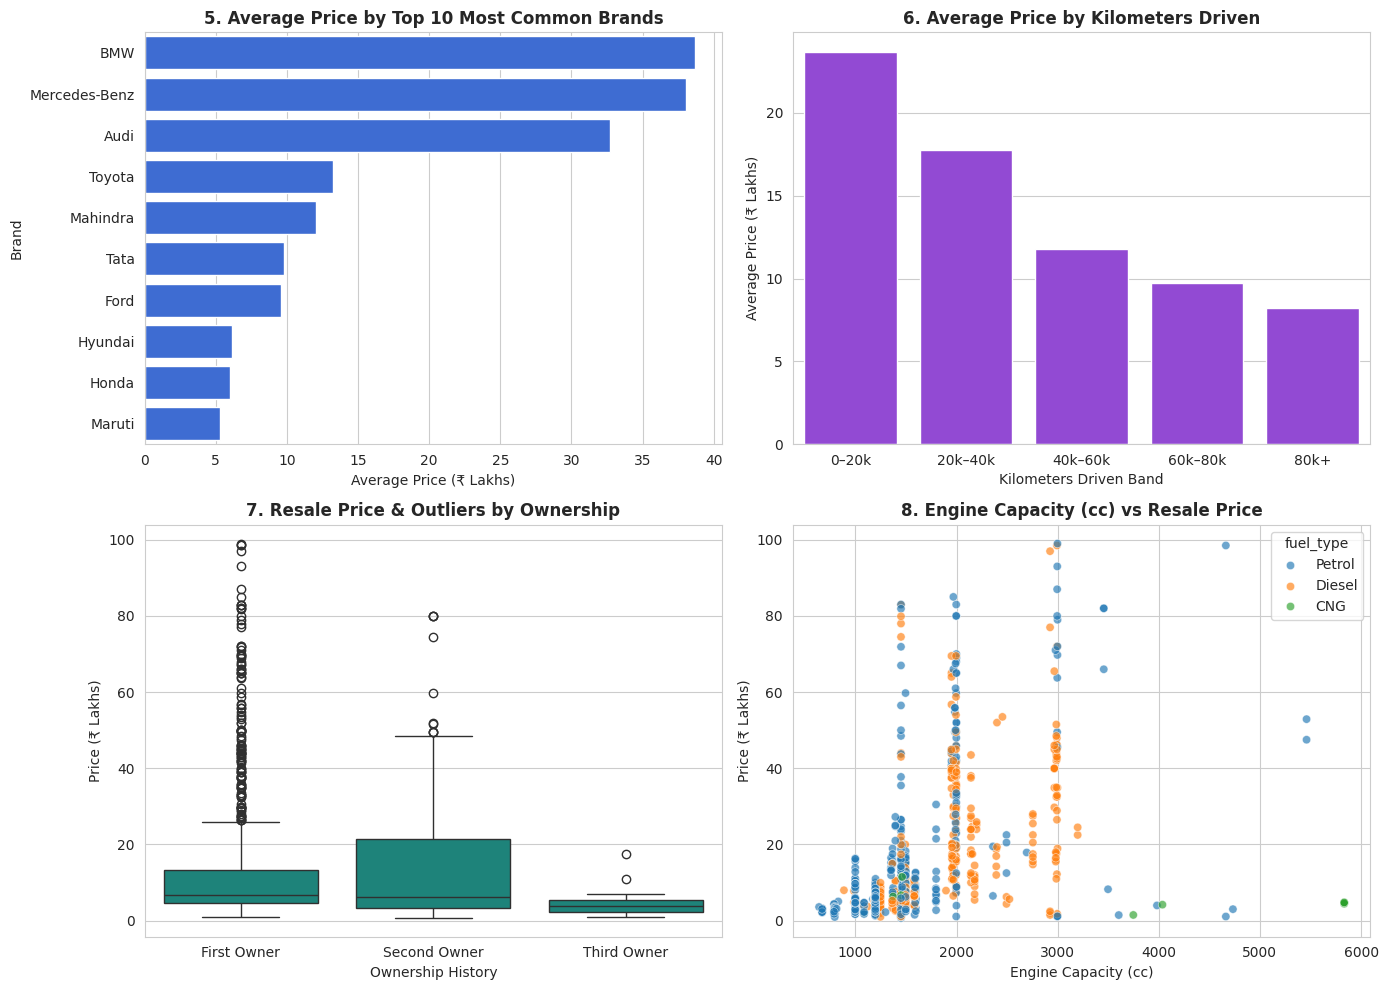

Saved 'phase1_eda_extended.png' successfully!


In [11]:
# Extended EDA: Charts 5 to 8 (completes the 8+ visuals requirement)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Chart 5: Average Price by Top 10 Most Common Brands
top10_brands = clean_df['brand'].value_counts().head(10).index
brand_avg = (
    clean_df[clean_df['brand'].isin(top10_brands)]
    .groupby('brand')['price_lakhs']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)
sns.barplot(data=brand_avg, y='brand', x='price_lakhs', color='#2563eb', ax=axes[0, 0])
axes[0, 0].set_title('5. Average Price by Top 10 Most Common Brands', fontweight='bold')
axes[0, 0].set_xlabel('Average Price (₹ Lakhs)')
axes[0, 0].set_ylabel('Brand')

# Chart 6: Average Price by Kilometers Driven Bands
bins = [0, 20000, 40000, 60000, 80000, float('inf')]
labels = ['0–20k', '20k–40k', '40k–60k', '60k–80k', '80k+']
kms_band = pd.cut(clean_df['kms_driven'], bins=bins, labels=labels, right=False)
kms_avg = clean_df.groupby(kms_band, observed=False)['price_lakhs'].mean().reset_index(name='price_lakhs')
kms_avg.columns = ['kms_band', 'price_lakhs']
sns.barplot(data=kms_avg, x='kms_band', y='price_lakhs', color='#9333ea', ax=axes[0, 1])
axes[0, 1].set_title('6. Average Price by Kilometers Driven', fontweight='bold')
axes[0, 1].set_xlabel('Kilometers Driven Band')
axes[0, 1].set_ylabel('Average Price (₹ Lakhs)')

# Chart 7: Resale Price & Outliers by Ownership (Boxplot)
owner_order = ['First Owner', 'Second Owner', 'Third Owner']
sns.boxplot(data=clean_df, x='ownership', y='price_lakhs', order=owner_order,
            color='#0d9488', ax=axes[1, 0])
axes[1, 0].set_title('7. Resale Price & Outliers by Ownership', fontweight='bold')
axes[1, 0].set_xlabel('Ownership History')
axes[1, 0].set_ylabel('Price (₹ Lakhs)')

# Chart 8: Engine Capacity vs Resale Price (by Fuel Type)
sns.scatterplot(data=clean_df, x='engine_cc', y='price_lakhs', hue='fuel_type',
                alpha=0.65, ax=axes[1, 1])
axes[1, 1].set_title('8. Engine Capacity (cc) vs Resale Price', fontweight='bold')
axes[1, 1].set_xlabel('Engine Capacity (cc)')
axes[1, 1].set_ylabel('Price (₹ Lakhs)')

plt.tight_layout()
plt.savefig('phase1_eda_extended.png', dpi=200, bbox_inches='tight')
plt.show()
print("Saved 'phase1_eda_extended.png' successfully!")

### 5. Preprocessing Plan for Phase 2 (ML Preparation) & Limitations

* **Target (`y`):** `price_lakhs` (Continuous — Regression task)
* **Numerical Features:** `car_age`, `kms_driven`, `mileage_kmpl`, `engine_cc`, `seats`, `km_per_year` → Median imputation + StandardScaler (for linear/distance models; tree models use raw scale).
* **Categorical Features:** `brand`, `fuel_type`, `transmission`, `ownership`, `insurance_validity` → One-Hot Encoding (grouping rare brands into `Other` to prevent high-dimensional sparsity).
* **Data Leakage Prevention:** Perform `train_test_split` **before** fitting any imputer, encoder, or scaler; fit transformations strictly on `X_train` and apply to `X_test` using a Scikit-learn `Pipeline` + `ColumnTransformer`.
* **Dataset Limitations:** No city/location column is present in this Kaggle CSV; `max_power(bhp)` duplicated `engine(cc)` and `torque(Nm)` had stripped decimals, so both were dropped rather than feeding corrupted specs into future models.

In [12]:
from google.colab import files
for f in ['cleaned_used_cars.csv', 'cleaned_used_cars.xlsx',
          'phase1_eda_dashboard.png', 'phase1_eda_extended.png']:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>